# Methoden en Technieken -- Blok 2

## Datapunt 2a,

In deze opdracht worden de volgende leeruitkomsten getoetst, relevante termen zijn **dik** gedrukt:
- A2: Je stelt voor een AI-oplossing juridische, ethische, organisatorische, **functionele en
technische requirements** op.
- B1: Je **verkent en prepareert een dataset voor het trainen en testen van een AI-model en
kan de voor- en nadelen van het gebruik van een bestaande dataset onderbouwen**, rekening
houdend met technische en ethische randvoorwaarden.
- B2: Je **stelt op basis van requirements en data een geschikte architectuur voor een AI-
oplossing op en selecteert daarvoor passende AI-technieken gebruik makend van bijvoorbeeld**
machine learning, **deep learning**, kennisrepresentatie, computer vision en **natural language
processing**.
- B3: Je **ontwikkelt een nieuw** of voorgetraind **AI-model volgens een iteratief en systematisch
proces**.
- C2: **Je evalueert en beoordeelt de kwaliteit van een AI-model aan de hand van kwaliteitscriteria die in het vakgebied erkend worden** zoals robustness, **performance**, scalability,
explainability, **model complexity** en resource demand.

<hr>

- Dit is een individuele opdracht. Het is toegestaan met elkaar de opdracht te bespreken, maar iedereen schrijft zijn/haar eigen code en antwoorden. 
- Mocht je code van het internet hebben overgenomen/aangepast, vermeld dan de bron in het commentaar.
- Mocht je naar een bron verwijzen voor jouw argumentatie, vermeld dan de bron *en* copy-paste de specifieke uitspraak uit de bron waar je het argument op baseert. 
- Het gebruik van generatieve AI (Chat-GPT, etc...) is *alleen* toegestaan bij de voorbereiding op de opdracht. Denk hierbij aan activiteiten zoals brainstormen, of het maken van een plan. Het is niet toegestaan code of tekst van generative AI over te nemen. (Level 2 van de AI Assessment Scale)

**Bronnen volgens de opdracht:** bij overgenomen of aangepaste voorbeeldcode staat de herkomst in het commentaar boven de betreffende codecel. Bij een theoretisch argument geef ik de bron en een korte letterlijke uitspraak uit de bron, gevolgd door de betekenis daarvan voor mijn eigen keuze. De gegevens en grafieken uit het eigen experiment zijn als eigen resultaten herkenbaar.



## De opdracht

In de slides van les 3 staat hoe een Engels - Nederlands vertaalmodel gemaakt wordt met een transformer-encoder en -decoder. Zie ook hoofdstuk 15 uit Deep Learning with Python (derde editie).

### Deel 1
#### Deel 1a
Maak dit model na en fit dit model.

## Deel 1a — Het model namaken uit de les

### Aanpak
In deze notebook kun je lezen hoe een Transformer-model wordt getrained om engelse zinnen naar het nederlands te vertalen. Ik heb de feedback om mijn aanpak beter te onderbouwen en uit te leggen waarom ik bepaalde keuzes maak in het model trainen. Ik zal de opdracht daarom niet alleen systematisch uitvoeren maar ook onderbouwen waarom ik specifieke keuzes maak, waarden kies en itteraties uitvoer.

Aangezien de opdracht specifiek verwijst naar de encoder-decoder model uit les 3, begin ik daarom met het reproduceren van die implementatie. Dit wordt mijn baseline. in het tweede deel kan ik vaststellen of aanassingen en itteraties iets opleveren. Om deze manier kan ik achteraf een verbetering constateren aan de hand van een eerlijke vergelijking en uiteenzetting.

Ik ga in 4 stappen tewerk. Eerst onderzoek ik de opbouw van de zinsparen en maak ik een train, validatie en test split. Daarna ga ik de teksten omzetten naar nummerieke representaties, bouw ik de encoder-decoder tranformator en train ik het model. En als laatst kijk ik naar de leercurve en controleer ik en paar van de gegenereerd vertalingen ter varivicatie. Op basis van die resultaten kan ik bepalen welke verbeteringen interresant zijn.

Zoals eerder gezegt. De baseline is gebaseerd op de `blok2les03.ipynb`, onderdelen _Eng-Ned vertaaldataset_, _Transformer decoder_, _PositionalEmbedding_, en de _Transformer, training_. De code is grotendeels gebaseerd op de notebook van F. Chollet _Deep learning with python_, hoofdstuk 15.

### Requirements voor de baseline

De opdracht is een *sequence-to-sequence learning*-probleem: een reeks Engelse tokens wordt omgezet naar een reeks Nederlandse tokens. Ik wil vooraf duidelijk maken wanneer ik de opdracht technisch goed heb uitgevoerd. Bij de eisen maak ik onderscheid tussen wat het model moet kunnen en hoe ik controleer of de aanpak betrouwbaar genoeg is.

| Nr. | Requirement | Hoe controleer ik dit? |
|---|---|---|
| F1 | Het model moet een Engelse zin omzetten naar een Nederlandse zin. | Ik laat het model vertalingen genereren en vergelijk die met de referentiezinnen. |
| F2 | Het model moet rekening houden met de context en woordvolgorde in de brontekst. | Ik gebruik een encoder-decoder met attention en positionele embeddings, en bekijk concrete foutvoorbeelden. |
| T1 | De data moet gescheiden blijven voor trainen, valideren en testen. | Ik controleer de 70/15/15-split en pas de vectorizers uitsluitend aan op de trainingsdata. |
| T2 | De eerste versie moet vergelijkbaar zijn met het lesvoorbeeld. | Ik leg de architectuur, hyperparameters en gebruikte code vast. |
| T3 | Ik moet kunnen zien of het model leert en of het overfit. | Ik vergelijk de training- en validatieloss over alle epochs. |
| T4 | Ik wil de resultaten terug kunnen vinden zonder opnieuw te trainen. | Ik bewaar het model, de history, figuren en voorbeeldvertalingen. |

Een belangrijk punt uit mijn eerdere feedback is dat requirements niet alleen op papier moeten staan, maar ook echt gecontroleerd moeten worden. Daarom kom ik bij de resultaten op deze eisen terug. Een harde eis zoals 'minstens 90% accuracy' stel ik nu nog niet: ik weet immers nog niet of token-accuracy iets zegt over de kwaliteit van hele vertalingen.

### Experimentomgeving

Ik gebruik de Transformerimplementatie uit les 3 als baseline. De training is lokaal uitgevoerd met **TensorFlow 2.21.0** en **Keras 3.15.1** op mijn CPU omdat ik het op mijn GPU niet werkend kreeg met Windows. De code legt een random seed vast maar dat betekent niet dat herhaling op andere hardware tot exact dezelfde uitkomsten gaat leiden. De daadwerkelijk behaalde waarden en resultaten heb ik opgeslagen en gebruik ik hieronder als mijn meetresultaten.

In [1]:
import random
import string
import re
import json
import zipfile
from pathlib import Path

import keras
from keras import layers, ops
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Vaste seed voor herhaalbare resultaten
SEED = 1407
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Mappen voor data, modellen en resultaten
DATA_DIR = Path("data/raw")
MODEL_DIR = Path("models")
RESULTS_DIR = Path("results")
FIGURES_DIR = RESULTS_DIR / "figures"

for folder in (DATA_DIR, MODEL_DIR, RESULTS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

# Check of een GPU beschikbaar is
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0 | Keras: 3.15.1
GPU: []


### 1. Dataset laden en splitsen

Eerst wil ik weten welke data ik precies aan het model geef. Ik gebruik de Engels-Nederlandse zinnen uit de ManyThings/Anki-verzameling. 

In het tekstbestand staan Engelse en Nederlandse zinnen naast elkaar. Ik gebruik de eerste twee tabgescheiden velden en zet om de Nederlandse zin de tokens `[start]` en `[end]`. De decoder kan daarmee leren waar een vertaling begint en wanneer deze klaar is.

**Waarom eerst splitsen?** Als ik alle data gebruik bij de voorbereiding van mijn model, kan er ongemerkt informatie uit de testset in mijn keuzes terechtkomen. Ik split daarom eerst met een vaste seed in **70% training, 15% validatie en 15% test**. De validatieset gebruik ik om de modelontwikkeling te volgen, maar de testset houd ik voorlopig helemaal apart.

De code leest **84.999 zinsparen** in en verdeelt die als volgt:

| Onderdeel | Aantal zinsparen | Gebruik |
|---|---:|---|
| Training | 59.501 | Modelgewichten leren en woordenschat opbouwen |
| Validatie | 12.749 | Tijdens training prestaties volgen |
| Test | 12.749 | Gereserveerd voor de uiteindelijke evaluatie |

Deze verdeling levert veel voorbeelden op om te trainen en houdt tegelijkertijd twee afzonderlijke subsets over. Het is wel een willekeurige splitsing: ik heb nog niet gecontroleerd of vrijwel identieke zinnen in meerdere subsets voorkomen. Daar kom ik bij deel 1b op terug.

**Bron:** `data/raw/nld-eng/_about.txt` en [ManyThings/Anki](https://www.manythings.org/anki/).

In [2]:
# Dataset inladen (bron: ManyThings / Tatoeba, https://www.manythings.org/anki/)
dataset_path = DATA_DIR / "nld-eng" / "nld.txt"

if not dataset_path.is_file():
 raise FileNotFoundError(
 f"Dataset niet gevonden: {dataset_path.resolve()}\n"
 "Controleer of het bestand aanwezig is in de folderstructuur "
 "en of het notebook vanuit de hoofdmap van de opdracht draait."
 )

print("Dataset gevonden:", dataset_path.resolve())

# Engelse en Nederlandse zinnen met start- en eindtokens
text_pairs = []
with open(dataset_path, encoding="utf-8") as f:
 for line in f:
 fields = line.rstrip("\r\n").split("\t")
 if len(fields) >= 2 and fields[0] and fields[1]:
 text_pairs.append((fields[0], f"[start] {fields[1]} [end]"))

assert text_pairs, "Geen zinsparen ingelezen: controleer het datasetbestand."
# Zinsparen verdelen in train, validatie en test
random.Random(SEED).shuffle(text_pairs)
val_samples = int(0.15 * len(text_pairs))
train_samples = len(text_pairs) - 2 * val_samples
train_pairs = text_pairs[:train_samples]
val_pairs = text_pairs[train_samples:train_samples + val_samples]
test_pairs = text_pairs[train_samples + val_samples:]
print("Totaal:", len(text_pairs), "| train:", len(train_pairs), "| validatie:", len(val_pairs), "| test:", len(test_pairs))
print("Voorbeeld:", train_pairs[0])

Dataset gevonden: C:\Users\Wander\OneDrive\Documenten\0. school\MAAI\maai\BLOK 2\M&T\MAAI_MenT\data\raw\nld-eng\nld.txt
Totaal: 84999 | train: 59501 | validatie: 12749 | test: 12749
Voorbeeld: ('You have such a beautiful house.', '[start] Je hebt zo’n mooi huis. [end]')


### 2. Een eerste verkenning van de data

Voordat ik met het model begin, wil ik de dataset beter begrijpen. Vooral de **zinslengte** vind ik interessant. In les 3 wordt namelijk een maximale sequentielengte van twintig tokens gebruikt. Wanneer veel zinnen langer zijn, zou een deel van de tekst worden afgekapt.

Ik maak daarom twee grafieken. De eerste controleert of de dataset inderdaad volgens de gekozen verhouding is verdeeld. In de tweede kijk ik hoe de lengtes van Engelse en Nederlandse zinnen binnen de **trainingsset** verdeeld zijn.

Ik tel voor deze eerste verkenning woorden op basis van spaties. Dat is niet precies hetzelfde als het aantal tokens na de `TextVectorization`-stap. Toch helpt deze verdeling om in te schatten of de maximale sequentielengte van twintig een beperking kan vormen.

**Interpretatie.** De dataset bevat 59.501 trainingszinnen en twee even grote sets van 12.749 zinnen voor validatie en test, wat aansluit bij de bedoelde splitsing. De zinslengtegrafiek gebruik ik vooral als controle op de keuze uit les 3. Ik kan nog niet concluderen dat twintig tokens voor iedere zin voldoende is; om dat vast te stellen moet ik het daadwerkelijke aandeel afgekorte tokenreeksen meten.

Dat is meteen een mogelijke vervolganalyse: als veel zinnen worden afgekapt, kan dit de vertaalkwaliteit beïnvloeden. Voor de baseline laat ik de instelling bewust gelijk aan het lesvoorbeeld.

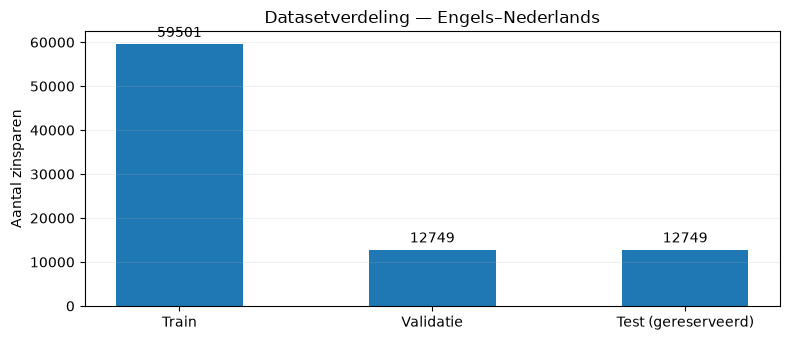

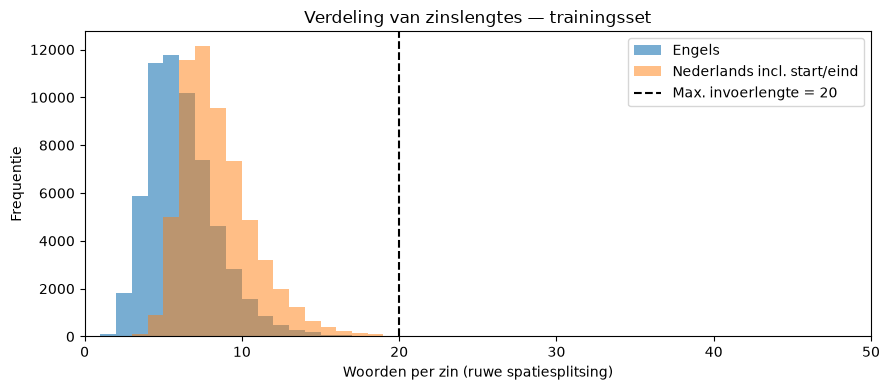

In [3]:
# Datasetverdeling visualiseren
split_counts = {"Train": len(train_pairs), "Validatie": len(val_pairs), "Test (gereserveerd)": len(test_pairs)}
fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.bar(split_counts.keys(), split_counts.values(), width=0.5)
ax.bar_label(bars, padding=3)
ax.set_title("Datasetverdeling — Engels–Nederlands")
ax.set_ylabel("Aantal zinsparen")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_datasetverdeling.png", dpi=160)
plt.show()

# Zinslengtes van de trainingsset bekijken
english_lengths = np.array([len(s.split()) for s, _ in train_pairs])
dutch_lengths = np.array([len(s.split()) for _, s in train_pairs])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(english_lengths, bins=range(1, 51), alpha=0.6, label="Engels")
ax.hist(dutch_lengths, bins=range(1, 51), alpha=0.5, label="Nederlands incl. start/eind")
ax.axvline(20, linestyle="--", color="black", label="Max. invoerlengte = 20")
ax.set_xlim(0, 50)
ax.set_xlabel("Woorden per zin (ruwe spatiesplitsing)")
ax.set_ylabel("Frequentie")
ax.set_title("Verdeling van zinslengtes — trainingsset")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_zinslengtes.png", dpi=160)
plt.show()

### 3. Tekst omzetten naar tokens

Een Transformer kan niet rechtstreeks met tekst rekenen. Daarom moet ik de zinnen eerst omzetten naar getallen. Ik gebruik hiervoor de `TextVectorization`-laag uit Keras. Deze bouwt een woordenschat op en zet ieder woord om naar een token-ID.

De Engelse invoer krijgt een lengte van **20 tokens** en de Nederlandse doelzin **21 tokens**. Dat verschil komt door de manier waarop de decoder wordt getraind. Uit de Nederlandse reeks maak ik twee versies: de invoer zonder het laatste token en de gewenste uitvoer zonder het eerste token. Zo leert het model telkens het *volgende* Nederlandse token voorspellen. Dit heet *teacher forcing*.

Een eenvoudig voorbeeld: bij de decoderinvoer `[start] ik` hoort als volgende woord bijvoorbeeld `ben`. Tijdens het genereren krijgt de decoder die juiste vervolgwoorden niet meer cadeau, maar moet hij zijn eigen voorspellingen gebruiken.

De woordenschat stel ik **alleen op de trainingsset** af. Anders zou de vectorizer alvast woorden uit de validatie- of testset leren kennen. Ik gebruik ook een masker/weging voor paddingposities bij de accuracy, zodat opvulwaarden niet als gewone correcte woorden worden geteld.

Ik neem voor de baseline dezelfde grenzen uit les 3 over: een vocabulaire van **15.000 tokens** en een **batchgrootte van 64**. Ik kan later onderzoeken of die grenzen invloed hebben op langere zinnen of zeldzame woorden.

**Bronnen:** `Blok2_Les03.ipynb` en [Keras: TextVectorization](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/).
**Bron: Keras TextVectorization.** De documentatie vermeldt letterlijk: “A preprocessing layer which maps text features to integer sequences.” ([bron](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/)). Dit ondersteunt mijn keuze om de tekst eerst naar token-ID's om te zetten; de keuze voor 15.000 tokens is daarnaast overgenomen uit les 3 en niet uit deze uitspraak afgeleid.


In [4]:
# Tekst voorbereiden; [start] en [end] behouden
strip_chars = string.punctuation + "¿"
strip_chars = strip_chars.replace("[", "")
strip_chars = strip_chars.replace("]", "")

def custom_standardization(input_string):
    lowercase = tf.strings.lower(input_string)
    return tf.strings.regex_replace(
        lowercase, f"[{re.escape(strip_chars)}]", ""
    )

vocab_size = 15000
sequence_length = 20

# Tekst naar tokens omzetten (bron: Keras TextVectorization, https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/)
english_tokenizer = layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length,
)
dutch_tokenizer = layers.TextVectorization(
    max_tokens=vocab_size,
    output_mode="int",
    output_sequence_length=sequence_length + 1,
    standardize=custom_standardization,
)
train_english_texts = [pair[0] for pair in train_pairs]
train_dutch_texts = [pair[1] for pair in train_pairs]
# Woordenschat opbouwen met alleen trainingsdata
english_tokenizer.adapt(train_english_texts)
dutch_tokenizer.adapt(train_dutch_texts)

In [5]:
# Teacher forcing en batches uit Blok2_Les03.ipynb
batch_size = 64

# Decoderinput en doel één token verschuiven
def format_dataset(eng, spa):
    eng = english_tokenizer(eng)
    spa = dutch_tokenizer(spa)
    features = {"english": eng, "dutch": spa[:, :-1]}
    labels = spa[:, 1:]
    sample_weights = labels != 0
    return features, labels, sample_weights

# TensorFlow-datasets klaarmaken
def make_dataset(pairs):
    eng_texts, spa_texts = zip(*pairs)
    eng_texts = list(eng_texts)
    spa_texts = list(spa_texts)
    dataset = tf.data.Dataset.from_tensor_slices((eng_texts, spa_texts))
    dataset = dataset.batch(batch_size)
    dataset = dataset.map(format_dataset, num_parallel_calls=4)
    return dataset.cache().shuffle(2048, seed=SEED).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_pairs)
val_ds = make_dataset(val_pairs)

for features, targets, weights in train_ds.take(1):
    print('Encoder:', features['english'].shape, 'Decoder:', features['dutch'].shape, 'Targets:', targets.shape)
    print('Paddinggewicht (eerste 10):', weights[0, :10].numpy())

Encoder: (64, 20) Decoder: (64, 20) Targets: (64, 20)
Paddinggewicht (eerste 10): [ True  True  True  True  True  True  True  True  True  True]


### 4. De Transformer-architectuur

Nu de tekst numeriek beschikbaar is, kan ik het model opbouwen. De opdracht vraagt om een **Transformer encoder-decoder**, zoals in les 3. Ik wil begrijpen wat de verschillende onderdelen doen, zodat ik later een gerichte verbetering kan voorstellen in plaats van zomaar parameters te veranderen.

De **encoder** leest de Engelse zin en maakt voor ieder token een representatie die rekening houdt met andere woorden in dezelfde zin. Dit gebeurt via *self-attention*. Dat lijkt me bij vertalen belangrijk: de betekenis van een woord hangt vaak af van de rest van de zin.

De **decoder** voorspelt de Nederlandse zin token voor token. Hij gebruikt daarvoor zowel de eerder bekende Nederlandse tokens als de informatie uit de encoder, via *cross-attention*. Tijdens training wordt *causal masking* gebruikt, zodat de decoder niet vooruit kan kijken naar Nederlandse woorden die hij op dat moment nog moet voorspellen.

Tot slot is **woordvolgorde** belangrijk. Attention legt niet vanzelf vast welk woord voor of achter een ander woord staat. Daarom voeg ik positionele embeddings toe.

De onderstaande drie klassen komen voort uit de voorbeeldimplementatie van les 3. Ik verander de architectuur nog niet, omdat ik anders niet goed kan bepalen of een latere aanpassing werkelijk verbetering brengt.

**Theoretische onderbouwing:** Vaswani et al. (2017), [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762), en de bij les 3 gebruikte behandeling van Transformers in François Chollet, *Deep Learning with Python*, hoofdstuk 15.

#### 4.1 Encoder

De encoder gebruikt multi-head self-attention om relaties tussen invoertokens te modelleren. Daarna verwerkt een feedforward-netwerk de representaties verder. De residual connections en layer normalization komen uit de modelopbouw in de les.
**Bron: Keras MultiHeadAttention.** De documentatie vermeldt letterlijk: “If `query`, `key,` `value` are the same, then this is self-attention.” ([bron](https://keras.io/api/layers/attention_layers/multi_head_attention/)). Dit verklaart de self-attention in de encoder; voor cross-attention gebruikt de decoder de encoderuitvoer als bron.


In [6]:
# Encoder met self-attention (bron: Blok2_Les03.ipynb)
class TransformerEncoder(keras.Layer):
    def __init__(self, hidden_dim, intermediate_dim, num_heads, **kwargs):
        super().__init__()
        key_dim = hidden_dim // num_heads
        self.self_attention = layers.MultiHeadAttention(num_heads, key_dim)
        self.self_attention_layernorm = layers.LayerNormalization()
        self.feed_forward_1 = layers.Dense(intermediate_dim, activation="relu")
        self.feed_forward_2 = layers.Dense(hidden_dim)
        self.feed_forward_layernorm = layers.LayerNormalization()

    def call(self, source, source_mask):
        residual = x = source
        mask = source_mask[:, None, :]
        x = self.self_attention(query=x, key=x, value=x, attention_mask=mask)
        x = x + residual
        x = self.self_attention_layernorm(x)
        residual = x
        x = self.feed_forward_1(x)
        x = self.feed_forward_2(x)
        x = x + residual
        x = self.feed_forward_layernorm(x)
        return x

#### 4.2 Decoder

Waar de encoder de Engelse bronzin verwerkt, moet de decoder een Nederlandse zin opbouwen. Met *causal self-attention* kijkt hij alleen naar eerder bekende Nederlandse tokens. Via *cross-attention* kan hij daarbij de context van de Engelse zin gebruiken. Dat onderscheid is belangrijk: zonder koppeling aan de Engelse invoer zou het model vooral leren hoe Nederlandse zinnen doorgaans lopen, niet wat de brontekst betekent.

In [7]:
# Decoder met causal en cross-attention (bron: Blok2_Les03.ipynb)
class TransformerDecoder(keras.Layer):
    def __init__(self, hidden_dim, intermediate_dim, num_heads, **kwargs):
        super().__init__()
        key_dim = hidden_dim // num_heads
        self.self_attention = layers.MultiHeadAttention(num_heads, key_dim)
        self.self_attention_layernorm = layers.LayerNormalization()
        self.cross_attention = layers.MultiHeadAttention(num_heads, key_dim)
        self.cross_attention_layernorm = layers.LayerNormalization()
        self.feed_forward_1 = layers.Dense(intermediate_dim, activation="relu")
        self.feed_forward_2 = layers.Dense(hidden_dim)
        self.feed_forward_layernorm = layers.LayerNormalization()

    def call(self, target, source, source_mask):
        residual = x = target
        x = self.self_attention(query=x, key=x, value=x, use_causal_mask=True)
        x = x + residual
        x = self.self_attention_layernorm(x)
        residual = x
        mask = source_mask[:, None, :]
        x = self.cross_attention(
            query=x, key=source, value=source, attention_mask=mask
        )
        x = x + residual
        x = self.cross_attention_layernorm(x)
        residual = x
        x = self.feed_forward_1(x)
        x = self.feed_forward_2(x)
        x = x + residual
        x = self.feed_forward_layernorm(x)
        return x

#### 4.3 Positionele embeddings

Een aandachtspunt bij attention is dat het mechanisme op zichzelf niet weet op welke positie een woord staat. Daarom combineer ik tokenembeddings met positie-informatie. Bij vertalen is dat belangrijk: een andere woordvolgorde kan immers de betekenis veranderen.

Deze klasse maakt die combinatie. Ik laat haar in de baseline gelijk aan de lesimplementatie.

**Bron:** Vaswani et al. (2017), [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762).
**Bron: Keras Embedding.** De documentatie vermeldt letterlijk: “Turns nonnegative integers (indexes) into dense vectors of fixed size.” ([bron](https://keras.io/api/layers/core_layers/embedding/)). Dit verklaart de token- en positie-embeddings in deze implementatie; waarom posities nodig zijn is aanvullend onderbouwd met Vaswani et al. (2017).


In [8]:
# Token- en positie-embeddings (bron: Blok2_Les03.ipynb)
class PositionalEmbedding(keras.Layer):
    def __init__(self, sequence_length, input_dim, output_dim, **kwargs):
        super().__init__()
        self.token_embeddings = layers.Embedding(input_dim, output_dim)
        self.position_embeddings = layers.Embedding(sequence_length, output_dim)

    def call(self, inputs):
        positions = ops.cumsum(ops.ones_like(inputs), axis=-1) - 1
        embedded_tokens = self.token_embeddings(inputs)
        embedded_positions = self.position_embeddings(positions)
        return embedded_tokens + embedded_positions

#### 4.4 Het model samenstellen

Ik zet de encoder en decoder nu aan elkaar. De instellingen zijn overgenomen uit les 3, zodat deze eerste versie een herkenbare baseline blijft.

| Hyperparameter | Waarde | Waarom hier gebruikt? |
|---|---:|---|
| Vocabulaire | 15.000 | Gelijk aan les 3; begrenst het aantal bekende tokens |
| Sequentielengte | 20 | Gelijk aan les 3; bepaalt maximale invoerlengte |
| Hidden-dimensie | 256 | Grootte van de tokenrepresentaties |
| Feedforward-dimensie | 2056 | Capaciteit van het feedforward-deel |
| Attention-heads | 8 | Meerdere attentionprojecties per laag |
| Dropout vóór output | 0,5 | Regularisatie om overfitting tegen te gaan |

Het modeloverzicht in de uitgevoerde code laat **14.447.272 parameters** zien. Dat is behoorlijk wat capaciteit voor een model dat ik op ongeveer zestigduizend zinsparen train. Ik kan daarmee nog niet concluderen dat het model te complex is, maar het is wel relevant wanneer ik straks de training- en validatiecurves vergelijk.

De naam van de decoderinvoer is `dutch`, zodat de code beter aansluit op de Engels-Nederlandse vertaaltaak. De werking is daardoor niet veranderd.

In [9]:
# Modelinstellingen uit Blok2_Les03.ipynb
hidden_dim = 256
intermediate_dim = 2056
num_heads = 8

# Encoder en decoder verbinden
source = keras.Input(shape=(None,), dtype="int32", name="english")
x = PositionalEmbedding(sequence_length, vocab_size, hidden_dim)(source)
encoder_output = TransformerEncoder(hidden_dim, intermediate_dim, num_heads)(
    source=x,
    source_mask=source != 0,
)

target = keras.Input(shape=(None,), dtype="int32", name="dutch")
x = PositionalEmbedding(sequence_length, vocab_size, hidden_dim)(target)
x = TransformerDecoder(hidden_dim, intermediate_dim, num_heads)(
    target=x,
    source=encoder_output,
    source_mask=source != 0,
)
x = layers.Dropout(0.5)(x)
target_predictions = layers.Dense(vocab_size, activation="softmax")(x)
transformer = keras.Model([source, target], target_predictions, name='Transformer_EN_NL_Baseline')
transformer.summary()
print('Aantal parameters:', transformer.count_params())

Model: "Transformer_EN_NL_Baseline"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 256) │  3,845,120 │ english[0][0]     │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dutch (InputLayer)  │ (None, None)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_encoder │ (None, None, 256) │  1,319,176 │ positional_embed… │
│ (TransformerEncode… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, None)      │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, None, 256) │  3,845,120 │ dutch[0][0]       │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_decoder │ (None, None, 256) │  1,582,856 │ transformer_enco… │
│ (TransformerDecode… │                   │            │ not_equal_1[0][0… │
│                     │                   │            │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, None, 256) │          0 │ transformer_deco… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, None,      │  3,855,000 │ dropout_3[0][0]   │
│                     │ 15000)            │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,447,272 (55.11 MB)

 Trainable params: 14,447,272 (55.11 MB)

 Non-trainable params: 0 (0.00 B)

Aantal parameters: 14447272


### 5. Training van de baseline

Voor het trainen gebruik ik **Adam** en **sparse categorical crossentropy**. De decoder voorspelt per positie een kansverdeling over de Nederlandse woordenschat; de loss vergelijkt die voorspelling met het juiste token-ID. Daarnaast houd ik de gewogen **token-accuracy** bij. Die maat laat zien hoe vaak het juiste token wordt voorspeld, maar niet of een hele Nederlandse zin grammaticaal of inhoudelijk klopt.

Ik train het model **30 epochs**, zodat ik goed kan zien hoe de resultaten zich ontwikkelen. Per epoch bereken ik ook de validatieloss en validatieaccuracy. Dat helpt om te herkennen wanneer extra training nog iets oplevert of juist tot overfitting leidt.

Ik behoud de oorspronkelijke instellingen en bewaar na afloop de modelgewichten en trainingsgeschiedenis. Hiermee kan ik straks een verbeterd model vergelijken met precies dezelfde baseline, zonder deze dertig epochs opnieuw uit te voeren.

**Bron:** `Blok2_Les03.ipynb` en [Keras: Model training API](https://keras.io/api/models/model_training_apis/).
**Bron: Keras Adam.** De documentatie vermeldt letterlijk: “Optimizer that implements the Adam algorithm.” ([bron](https://keras.io/api/optimizers/adam/)). Ik gebruik Adam in de baseline volgens les 3. De documentatie beschrijft de optimizer; ze bewijst niet dat Adam voor deze dataset de beste keuze is.

**Bron: Keras SparseCategoricalCrossentropy.** De documentatie vermeldt letterlijk: “We expect labels to be provided as integers.” ([bron](https://keras.io/api/losses/probabilistic_losses/)). Dit sluit aan op de integer token-ID's van de doelzinnen, zodat one-hot labels niet nodig zijn.


In [10]:
# Baseline trainen: 30 epochs
EPOCHS = 30
# Adam, crossentropy en accuracy (bron: https://keras.io/api/models/model_training_apis/)
transformer.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    weighted_metrics=["accuracy"],
)

history = transformer.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=val_ds,
    verbose=1,
)

# Model en trainingsgeschiedenis opslaan
transformer.save(MODEL_DIR / "transformer_baseline.keras")
with open(RESULTS_DIR / "transformer_baseline_history.json", "w", encoding="utf-8") as f:
    json.dump({key: [float(x) for x in values] for key, values in history.history.items()}, f, indent=2)
print("Model en trainingsgeschiedenis opgeslagen.")

Epoch 1/30


c:\venvs\maai-ment\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


930/930 ━━━━━━━━━━━━━━━━━━━━ 1079s 1s/step - accuracy: 0.4990 - loss: 1.1790 - val_accuracy: 0.6315 - val_loss: 0.7752
Epoch 2/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1116s 1s/step - accuracy: 0.6659 - loss: 0.6719 - val_accuracy: 0.6923 - val_loss: 0.6072
Epoch 3/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1438s 2s/step - accuracy: 0.7234 - loss: 0.4996 - val_accuracy: 0.7146 - val_loss: 0.5575
Epoch 4/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1173s 1s/step - accuracy: 0.7584 - loss: 0.4046 - val_accuracy: 0.7240 - val_loss: 0.5401
Epoch 5/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1188s 1s/step - accuracy: 0.7839 - loss: 0.3402 - val_accuracy: 0.7284 - val_loss: 0.5353
Epoch 6/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1102s 1s/step - accuracy: 0.8046 - loss: 0.2946 - val_accuracy: 0.7365 - val_loss: 0.5344
Epoch 7/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1092s 1s/step - accuracy: 0.8209 - loss: 0.2606 - val_accuracy: 0.7386 - val_loss: 0.5430
Epoch 8/30
930/930 ━━━━━━━━━━━━━━━━━━━━ 1087s 1s/step - accuracy: 0.8348 - loss: 0.2349 - val_accurac

### 6. Resultaten van de 30 epochs

Om te beoordelen of het model goed leert, vergelijk ik de **loss** en **accuracy** van de trainings- en validatieset. De loss geeft aan hoe groot de voorspelfout is, waarbij ook de zekerheid van de voorspelling meetelt. **Lager is beter.** De accuracy geeft aan hoeveel Nederlandse tokens correct worden voorspeld. **Hoger is beter.** Een hoge token-accuracy betekent niet automatisch dat de volledige vertaling goed is.

De resultaten komen uit `results/transformer_baseline_history.json`.

| Meetpunt | Resultaat |
|---|---:|
| Laagste validatieloss | **0,5344** bij epoch **6** |
| Hoogste validatieaccuracy | **74,37%** bij epoch **25** |
| Trainingsaccuracy bij epoch 30 | **92,77%** |
| Validatieaccuracy bij epoch 30 | **74,27%** |
| Trainingsloss bij epoch 30 | **0,0898** |
| Validatieloss bij epoch 30 | **0,6973** |

### Interpretatie van de grafiek

In de grafiek kijk ik vooral naar het verschil tussen de trainingswaarden en de validatiewaarden. De trainingsloss blijft dalen tot **0,0898**, terwijl de validatieloss vanaf **epoch 6** weer stijgt naar **0,6973**. Ook is de trainingsaccuracy met **92,77%** een stuk hoger dan de validatieaccuracy van **74,27%**. Dit wijst op **overfitting**: het model leert de trainingszinnen steeds beter, maar presteert daardoor niet beter op nieuwe zinnen.

Hier zit ook een afweging tussen loss en accuracy. De hoogste validatieaccuracy wordt pas bij **epoch 25** bereikt, maar de laagste validatieloss al bij **epoch 6**. Omdat de loss ook rekening houdt met hoe zeker het model van een voorspelling is, gebruik ik vooral de **validatieloss** om te bepalen wanneer verder trainen weinig meer oplevert. Ik controleer daarnaast de accuracy en de gegenereerde vertalingen om te beoordelen of het model ook inhoudelijk goede resultaten geeft.

Voor deel 2 lijkt **early stopping** daarom een logische verbetering. De volledige training van 30 epochs duurde op mijn laptop ongeveer **acht uur**, terwijl de validatieloss na epoch 6 niet meer verbetert. Met early stopping kan ik mogelijk rekentijd besparen en de beste modelgewichten bewaren. Hoeveel tijd dit werkelijk scheelt, moet ik nog testen.

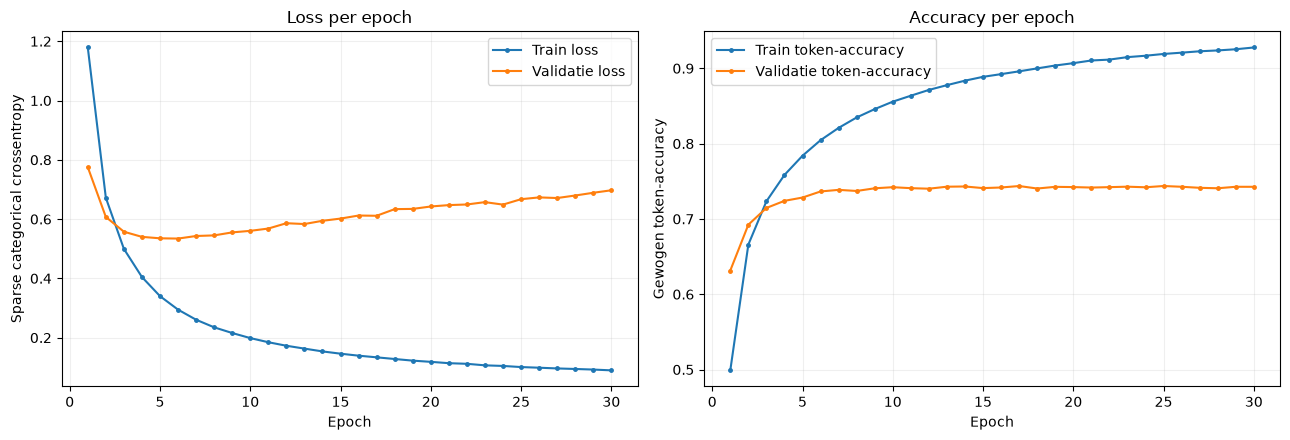

Beste validatie-loss: 0.5344 op epoch 6
Beste validatie-token-accuracy: 0.7437
Let op: token-accuracy is geen maat voor volledige vertaalcorrectheid.


In [11]:
# Learning curves uit de opgeslagen trainingswaarden
metrics = history.history
accuracy_key = next((k for k in metrics if k == "accuracy" or k.endswith("_accuracy") and not k.startswith("val_")), None)
val_accuracy_key = f"val_{accuracy_key}" if accuracy_key is not None else None
x = np.arange(1, len(metrics["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(x, metrics["loss"], marker="o", markersize=2.5, label="Train loss")
axes[0].plot(x, metrics["val_loss"], marker="o", markersize=2.5, label="Validatie loss")
axes[0].set(xlabel="Epoch", ylabel="Sparse categorical crossentropy", title="Loss per epoch")
axes[0].legend()
axes[0].grid(alpha=0.2)

if accuracy_key and val_accuracy_key in metrics:
    axes[1].plot(x, metrics[accuracy_key], marker="o", markersize=2.5, label="Train token-accuracy")
    axes[1].plot(x, metrics[val_accuracy_key], marker="o", markersize=2.5, label="Validatie token-accuracy")
    axes[1].legend()
axes[1].set(xlabel="Epoch", ylabel="Gewogen token-accuracy", title="Accuracy per epoch")
axes[1].grid(alpha=0.2)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_learning_curves.png", dpi=160)
plt.show()

# Epoch met laagste validatieloss bepalen
best_epoch = int(np.argmin(metrics["val_loss"])) + 1
print(f"Beste validatie-loss: {min(metrics['val_loss']):.4f} op epoch {best_epoch}")
if val_accuracy_key in metrics:
    print(f"Beste validatie-token-accuracy: {max(metrics[val_accuracy_key]):.4f}")
print("Let op: token-accuracy is geen maat voor volledige vertaalcorrectheid.")

### 7. Voorbeeldvertalingen controleren

Een token-accuracy van ongeveer 74% zegt nog niet hoe de volledige vertalingen eruitzien. Daarom wil ik ook een aantal zinnen zelf bekijken. Het model gebruikt *greedy decoding*: bij iedere stap wordt het token met de hoogste voorspelde kans gekozen.

Ik vergelijk acht Engelse zinnen uit de validatieset met hun Nederlandse referenties en de modelvertalingen. Dat blijft een beperkte steekproef; ik kan hier dus geen algemene foutpercentages uit afleiden. Wel kan ik zien **welke soorten fouten** voorkomen.

Ik verwacht dat bekende korte zinnen relatief eenvoudig zijn. Langere of minder gebruikelijke uitdrukkingen kunnen lastiger zijn, bijvoorbeeld wanneer de betekenis niet uit afzonderlijke woorden te reconstrueren is.

De code hieronder maakt die vergelijking en bewaart hem als `results/voorbeeldvertalingen_validatie.csv`.

In [12]:
# Token-ID's omzetten naar woorden
dutch_vocab = dutch_tokenizer.get_vocabulary()
dutch_index_lookup = dict(enumerate(dutch_vocab))

# Greedy decoding (bron: Blok2_Les03.ipynb)
def translate_sentence(english_sentence):
    encoder_tokens = english_tokenizer([english_sentence])
    decoded = "[start]"
    for i in range(sequence_length):
        decoder_tokens = dutch_tokenizer([decoded])[:, :-1]
        probabilities = transformer.predict([encoder_tokens, decoder_tokens], verbose=0)
        token_id = int(np.argmax(probabilities[0, i, :]))
        token = dutch_index_lookup[token_id]
        if token in ("[end]", ""):
            break
        decoded += " " + token
    return decoded.replace("[start]", "", 1).strip()

# Acht voorbeeldvertalingen uit de validatieset
sample_rng = random.Random(SEED)
examples = sample_rng.sample(val_pairs, k=min(8, len(val_pairs)))
rows = []
for english, reference in examples:
    rows.append({
        "Engels": english,
        "Referentie NL": reference.replace("[start]", "").replace("[end]", "").strip(),
        "Modelvertaling": translate_sentence(english),
    })
translations_df = pd.DataFrame(rows)
display(translations_df)
translations_df.to_csv(RESULTS_DIR / "voorbeeldvertalingen_validatie.csv", index=False)

print("Baseline gereed: controleer de learning curves en fouttypen vóór een modelverbetering.")

,Engels,Referentie NL,Modelvertaling
0,What a beautiful sight!,Wat een mooi uitzicht!,wat een mooi ogen uit
1,Does anybody else know about this?,Weet iemand anders hiervan?,weet iemand anders hiervan
2,I'll look forward to it.,Ik zal er naar uitkijken.,ik kijk ernaar uit
3,What do you enjoy doing in your free time?,Wat doet u graag in uw vrije tijd?,wat doe je graag in je vrije tijd
4,I need a job.,Ik heb een baan nodig.,ik heb een baan nodig
5,Do you have glaucoma?,Heeft u glaucoom?,heb je last van keelpijn
6,She is eight.,Zij is acht.,zij is acht
7,You must realize that prosperity does not last...,Je moet begrijpen dat welvaart niet eeuwig duurt.,je mag dat vanaf niet eeuwig duren


Baseline gereed: controleer de learning curves en fouttypen vóór een modelverbetering.


### 8. Interpretatie van de vertalingen en tussenconclusie

De acht gecontroleerde vertalingen laten een gemengd beeld zien. Bij **“I need a job.”** voorspelt het model **“ik heb een baan nodig”**, precies de betekenis van de referentiezin. Ook **“She is eight.”** wordt correct als **“zij is acht”** vertaald.

Bij andere zinnen valt vooral op dat het model soms **een redelijke parafrase** produceert. **“I'll look forward to it.”** wordt **“ik kijk ernaar uit”** in plaats van **“Ik zal er naar uitkijken.”**. Hoewel de formulering anders is, blijft de betekenis grotendeels behouden. Een beoordeling op exacte woordovereenkomst zou dit verschil mogelijk te streng behandelen. Ook **“What do you enjoy doing in your free time?”** wordt inhoudelijk begrijpelijk vertaald, maar het model gebruikt **“je”** waar de referentie **“u”** gebruikt.

Tegelijkertijd zijn er duidelijke fouten. **“Do you have glaucoma?”** wordt **“heb je last van keelpijn”**. Dat verandert de medische betekenis volledig. **“What a beautiful sight!”** wordt **“wat een mooi ogen uit”** en is grammaticaal en inhoudelijk niet goed. Bij de langere zin over welvaart ontstaat eveneens een onlogische vertaling. Het model kan dus woorden achter elkaar voorspellen zonder de volledige betekenis betrouwbaar te behouden.

**Wat concludeer ik hieruit?** De baseline leert wel degelijk vertaalpatronen, maar de kwaliteit is nog wisselend. De hoge trainingsaccuracy van 92,77% blijkt geen garantie voor goede zinsvertalingen. De combinatie van de learning curves en deze voorbeelden geeft mij twee duidelijke aanknopingspunten: **overfitting beperken** en **vertaalkwaliteit niet uitsluitend met token-accuracy beoordelen**.

### Controle van de oorspronkelijke requirements

| Requirement | Bevinding |
|---|---|
| F1 — Engelse zinnen vertalen | Aangetoond, maar de kwaliteit verschilt per zin |
| F2 — Context meenemen | De architectuur kan context verwerken; de foutvoorbeelden laten zien dat dit niet altijd goed lukt |
| T1 — Gescheiden datasets | Ja: 59.501 / 12.749 / 12.749; testset nog niet gebruikt |
| T2 — Vergelijkbare baseline | Ja: instellingen en architectuur zijn vastgelegd |
| T3 — Overfitting beoordelen | Ja: validatieloss verslechtert na epoch 6 |
| T4 — Resultaten bewaren | Ja: model, history, grafieken en voorbeeldvertalingen zijn opgeslagen |

### Wat neem ik mee uit eerdere feedback?

In mijn eerdere opdrachten kreeg ik onder meer feedback op het **verantwoorden van modelkeuzes**, het **scheiden van training en evaluatie**, het **onderbouwen van prestatiematen** en het **systematisch itereren**. Daarom wil ik voor deel 2 niet zomaar meerdere instellingen tegelijk wijzigen. Eerst formuleer ik op basis van deze resultaten een hypothese. Vervolgens verander ik één duidelijk afgebakende factor en vergelijk ik de uitkomsten met dezelfde validatieset.

### Bronnen bij deel 1a

- `Blok2_Les03.ipynb` — lesvoorbeeld, modelarchitectuur en trainingsinstellingen.
- `results/transformer_baseline_history.json` — eigen trainingsresultaten van 30 epochs.
- `results/voorbeeldvertalingen_validatie.csv` — eigen kwalitatieve evaluatie.
- Vaswani et al. (2017), [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) — werking van Transformer en attention.
- Chollet, *Deep Learning with Python*, hoofdstuk 15 — boek dat bij de opdracht is genoemd.
- [Keras: TextVectorization](https://keras.io/api/layers/preprocessing_layers/text/text_vectorization/) en [Keras: Model training API](https://keras.io/api/models/model_training_apis/) — documentatie van gebruikte functies.

#### Deel 1b
Bespreek de voor- en nadelen van de gebruikte dataset.

### Deel 1b — Voor- en nadelen van de dataset

Ik wil niet alleen kijken naar de hoeveelheid data, maar ook naar de vraag of deze geschikt is voor een vertaalmodel. De zinnen komen volgens `_about.txt` uit **Tatoeba**, via **ManyThings/Anki**. In diezelfde documentatie waarschuwt de aanbieder dat de zinnen fouten kunnen bevatten, ondanks een selectie op zinnen van moedertaalsprekers en nagekeken Engelse voorbeelden.

**Een voordeel** is dat ik direct gekoppelde Engels-Nederlandse vertaalparen heb. Daarmee kan ik een supervised encoder-decodermodel trainen zonder eerst zelf vertalingen te annoteren. De dataset is bovendien toegankelijk en staat in de folderstructuur van de opdracht, waardoor de voorbereiding goed herhaalbaar is. Het aantal van **84.999 paren** biedt genoeg voorbeelden om een serieuze baseline te trainen.

**Een nadeel** is dat ik niet weet hoe representatief deze losse zinnen zijn voor bijvoorbeeld lange documenten of formele zakelijke taal. Ook kunnen bij één Engelse zin meerdere Nederlandse vertalingen correct zijn. Een automatische maat die alleen naar de referentie kijkt kan een goede alternatieve formulering als fout behandelen. Dat zie ik bijvoorbeeld terug bij de vertaling van **“I'll look forward to it.”**: de gegenereerde zin wijkt af, maar blijft inhoudelijk redelijk.

Daarnaast is de kwaliteit niet volledig gegarandeerd. Een ander aandachtspunt is dat **dubbele of sterk vergelijkbare zinnen** mogelijk in verschillende subsets belanden bij een willekeurige splitsing. Ik heb dat risico nog niet gekwantificeerd; ik kan dus niet stellen dat er daadwerkelijk sprake is van datalekken. Een volgende controle zou zijn om identieke Engelse bronzinnen over de subsets heen te tellen.

Tot slot heeft de data ook een **juridische randvoorwaarde**. Het meegeleverde `_about.txt` verwijst naar **CC BY 2.0** en vraagt om attributie van ManyThings en Tatoeba. Bij hergebruik moet ik die naamsvermelding en de licentievoorwaarden respecteren.

**Mijn conclusie:** voor het namaken van de Transformer uit les 3 is deze dataset geschikt, omdat ik voldoende tweetalige voorbeelden heb. Maar het is geen garantie dat het model straks betrouwbare vertalingen maakt in andere contexten. Vooral de beperkte context, mogelijke fouten en verschillen tussen correcte vertalingen moet ik meenemen in de evaluatie.

**Bronnen:** `data/raw/nld-eng/_about.txt`, [ManyThings/Anki](https://www.manythings.org/anki/), [Tatoeba](https://tatoeba.org/) en [Creative Commons BY 2.0](https://creativecommons.org/licenses/by/2.0/).

### Deel 2
We willen dit model nu verbeteren. Bedenk een (mogelijke) verbetering. Het is niet de bedoeling dat je bestaande pretrained modellen gebruikt. Train alles zelf.

#### Deel 2a
Stel een korte lijst van eisen op waar jouw verbeterde model aan hoort te voldoen. 

### Hoofdstuk 1 — Resultaten van de baseline en mogelijke verbeteringen

In deel 1 heb ik de Transformer uit les 3 getraind voor 30 epochs. Voordat ik iets aanpas, wil ik eerst kijken welke problemen uit deze resultaten naar voren komen. Op basis daarvan kan ik bepalen welke verbeteringen ik wil onderzoeken.

| Wat valt mij op in de baseline? | Wat wil ik verbeteren? |
|---|---|
| De validatieloss is het laagst bij **epoch 6 (0,5344)** en stijgt daarna tot **0,6973** bij epoch 30, terwijl de trainingsloss blijft dalen. | **Minder overfitting** en niet onnodig lang trainen. |
| De hoogste validatieaccuracy is **74,37%**, maar dit gaat over losse tokens en niet over complete zinnen. | **Betere volledige vertalingen**, niet alleen een hoge token-accuracy. |
| *What a beautiful sight!* wordt vertaald als *wat een mooi ogen uit*. | **Natuurlijkere Nederlandse zinnen**. |
| *Do you have glaucoma?* wordt vertaald als *heb je last van keelpijn*. | **Betere woordkeuzes** en behoud van de betekenis. |
| De langere zin over welvaart wordt niet goed vertaald. | **Betere verwerking van langere of lastigere zinnen**. |
| Het model heeft **14.447.272 parameters** en de training van 30 epochs duurde op mijn laptop ongeveer **acht uur**. | Een **betere verhouding tussen modelkwaliteit en rekentijd**. |

Deze resultaten laten niet automatisch zien waardoor iedere vertaalfout ontstaat. Zo kan de fout bij *glaucoma* komen door beperkte trainingsvoorbeelden, tokenization of het model zelf. Ik beschouw dit daarom als mogelijke verklaringen die ik met gerichte experimenten wil onderzoeken.

#### Eisen voor de volgende iteraties (deel 2a)

- Ik wil bij iedere iteratie **één onderdeel aanpassen**, zodat ik het resultaat met de baseline kan vergelijken.
- Ik houd dezelfde **train-, validatie- en testsplit** aan. De testset blijft buiten de keuze van verbeteringen.
- Ik kijk naar **validatieloss en token-accuracy**, maar controleer ook of de **gegenereerde vertalingen inhoudelijk beter** worden.
- Ik houd rekening met **trainingstijd en modelcomplexiteit**, omdat ik de experimenten lokaal uitvoer.

Ik wil vooral voorkomen dat ik veel tijd besteed aan een complexere techniek zonder eerst te controleren of een eenvoudige aanpassing al verbetering oplevert.

#### Deel 2b
Licht het volgende toe:
- Welke verbetering je uitvoert en waarom je denkt dat dit voor een verbetering zal zorgen.
- Welke maat je gebruikt om de verbetering te meten, en waarom.

Houd je antwoorden kort en bondig.

### Hoofdstuk 2 — Mogelijke verbetertechnieken

Op basis van de baseline heb ik bekeken welke technieken kunnen helpen om het model te verbeteren. Ik begin steeds met **wat ik wil verbeteren**, daarna **wat daarvoor moet veranderen** en vervolgens **welke techniek ik kan gebruiken**.

| Wat wil ik verbeteren? | Wat moet er veranderen om dit te bereiken? | Techniek |
|---|---|---|
| **1. Minder overfitting en korter trainen** | Stoppen wanneer de validatieloss niet meer verbetert en de beste gewichten bewaren. | `EarlyStopping()` |
| **2. Betere en natuurlijkere vertalingen** | Meerdere mogelijke woordreeksen vergelijken in plaats van steeds alleen het waarschijnlijkste volgende woord kiezen. | Beam search |
| **3. Betere generalisatie** | Onderzoeken of een andere dropoutwaarde dan 0,5 het overfittingprobleem vermindert. | Dropout tuning |
| **4. Betere verwerking van onbekende en zeldzame woorden** | Woorden opsplitsen in kleinere woorddelen die het model kan herkennen. | Subword-tokenization (BPE) |
| **5. Betere kwaliteit van trainingsdata** | Dubbele, foutieve en ongeschikte zinsparen opsporen en waar nodig verwijderen. | Data cleaning |
| **6. Betere balans tussen modelcomplexiteit en prestaties** | Het aantal hidden dimensions of attention-heads gericht veranderen. | Hyperparameter tuning |

#### Bronnen die deze mogelijkheden ondersteunen

- **Early stopping:** Keras beschrijft dit als: “Stop training when a monitored metric has stopped improving.” ([Keras EarlyStopping](https://keras.io/api/callbacks/early_stopping/)). Dit past bij de stijgende validatieloss na epoch 6. Met `restore_best_weights=True` kan ik de beste gewichten bewaren.
- **Beam search:** In de documentatie van Google seq2seq staat: “beam search keeps several hypotheses”. ([Google seq2seq — decoding](https://github.com/google/seq2seq/blob/master/docs/nmt.md#decoding-with-beam-search)). Daarom wil ik meerdere mogelijke vertalingen vergelijken. Dit kan zonder opnieuw te trainen, maar het genereren zelf kan langzamer worden.
- **Dropout:** Keras geeft aan dat dropout tijdens training willekeurig een deel van de inputs op nul zet, “which helps prevent overfitting.” ([Keras Dropout](https://keras.io/api/layers/regularization_layers/dropout/)). Dit ondersteunt het testen van een andere dropoutwaarde.
- **Subword-tokenization:** Hugging Face beschrijft dat “rare or unknown words decompose into subwords.” ([Hugging Face — tokenization](https://huggingface.co/docs/transformers/main/tokenizer_summary)). Hierdoor kan ik onderzoeken of het model onbekende woorden beter verwerkt.
- **Data cleaning:** De toelichting bij de gebruikte dataset (`data/raw/nld-eng/_about.txt`) vermeldt letterlijk: “The data from the Tatoeba Project contains errors.” Daarom is het zinvol om foutieve en dubbele voorbeelden te controleren.
- **Modelcomplexiteit:** TensorFlow bespreekt bij overfitting het effect van een kleiner model en regularisatie. ([TensorFlow — Overfit and underfit](https://www.tensorflow.org/tutorials/keras/overfit_and_underfit)). Dit is een reden om de capaciteit te onderzoeken, maar een groter of kleiner model geeft niet automatisch betere vertalingen.

#### Prioritering op haalbaarheid en tijd

Ik wil de technieken niet allemaal tegelijk uitvoeren. Ik begin met de technieken die relatief eenvoudig zijn en waarvoor ik weinig of geen nieuwe training nodig heb. Daarna ga ik pas verder met aanpassingen die mogelijk opnieuw uren rekentijd kosten.

| Prioriteit | Techniek | Haalbaarheid en verwachte tijd |
|---|---|---|
| **1** | **Beam search** | Het bestaande model blijft hetzelfde; alleen de manier van vertalen verandert. Geen nieuwe training nodig. |
| **2** | **Early stopping** | Eenvoudig toe te voegen, maar ik moet wel een nieuw model trainen. De training kan eerder stoppen dan bij 30 epochs. |
| **3** | **Dropout tuning** | Kleine wijziging in de modelinstellingen, maar voor een eerlijke vergelijking moet ik opnieuw trainen. |
| **4** | **Data cleaning** | Eerst de data controleren; daarna waarschijnlijk opnieuw trainen om het effect op de vertaalkwaliteit te meten. |
| **5** | **Subword-tokenization** | De voorbereiding en woordrepresentaties veranderen. Hierdoor moet ik een nieuwe modelversie trainen. |
| **6** | **Hyperparameter tuning** | Verschillende modelgroottes vergelijken kan meerdere volledige trainingen vragen en daardoor veel tijd kosten. |

De volgorde is gebaseerd op mijn inschatting van **implementatiemoeilijkheid en rekentijd**. Het is nog geen gemeten vergelijking. Zo is beam search sneller uit te proberen omdat ik het bestaande model kan gebruiken. Early stopping vereist wel een nieuwe training, maar is qua code relatief eenvoudig.

**Grenzen van mijn onderzoek:** de baseline heeft ongeveer **acht uur** nodig gehad voor 30 epochs. Ik wil daarom eerst onderzoeken of de eenvoudigere technieken daadwerkelijk verbetering opleveren. Als de volgende experimenten te veel tijd kosten, stop ik met verdere verbeteringen. Ik beschrijf dan welke technieken ik wel en niet heb kunnen testen en waarom. Zo kan ik de uitgevoerde iteraties goed evalueren in plaats van veel nieuwe trainingen te starten zonder de resultaten te beoordelen.

#### Hoe bepaal ik of een verbetering werkt? (deel 2b)

Bij **early stopping, dropout en andere trainingswijzigingen** vergelijk ik de validatieloss, token-accuracy, vertaalkwaliteit en rekentijd. Bij **beam search** verandert de training niet, dus blijven de trainingsloss en validatieloss gelijk voor hetzelfde model. Daar kijk ik juist naar de **kwaliteit van de gegenereerde vertalingen**. Ik gebruik daarvoor dezelfde Engelse voorbeeldzinnen en referenties als bij de baseline.

Ik verander steeds maar één onderdeel per experiment. Pas wanneer ik de resultaten heb bekeken, bepaal ik of ik doorga met de volgende techniek. Daarbij houd ik de oorspronkelijke baseline apart, zodat de vergelijking eerlijk blijft.

#### Deel 2c
Train dit verbeterde model.

### Deel 3
#### Deel 3a
Evalueer het model.

#### Deel 3b
Bespreek het volgende.
- Hoeveel je model verbeterd (of verslechterd) is
- In het geval van geen verbetering, een mogelijke verklaring waarom het niet werkte.
- Licht toe wat je volgende stap zou zijn om betere resultaten te halen. Deze stap hoef je niet uit te voeren, maar wees wel specifiek en verantwoord het met jouw resultaten.

Houd je antwoorden kort en bondig.

### Deel 3b — Discussie en vervolgstap

Dit onderdeel werk ik uit nadat het verbeterde model daadwerkelijk is getraind. Ik wil dan niet alleen een verschil in scores noemen, maar ook uitleggen **hoe groot** dat verschil is en wat ik er wel of niet uit mag concluderen.

Ik vergelijk de baseline en de nieuwe aanpak met dezelfde datasplit en dezelfde meetwaarden. Daarbij kijk ik naar het absolute verschil in validatieloss en accuracy, de benodigde epochs en concrete vertaalvoorbeelden. Als de verbetering klein is of uitblijft, onderzoek ik of de gekozen ingreep wel bij het oorspronkelijke probleem past.

Als vervolgstap zou ik bijvoorbeeld de **werkelijke tokenlengtes en het percentage afgekorte zinnen** analyseren. Als blijkt dat veel informatie verloren gaat bij twintig tokens, kan een grotere sequentielengte logisch zijn. Die wijziging zou ik in een aparte iteratie testen, zodat ik het effect kan onderscheiden van early stopping.

**Status:** er zijn nog geen resultaten van een verbeterd model. Ik vul daarom nog geen verbeterpercentages of definitieve conclusie in.